In [125]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
import numpy as np
from scipy import stats
from sklearn.metrics import classification_report
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import precision_recall_curve

TRAINING DATA

In [126]:
# load training dataset

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

columns = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status", "occupation",
           "relationship", "race", "sex", "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"]

ds_train = pd.read_csv(url, names=columns, na_values=" ?", skipinitialspace=True)
print(ds_train.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB
None


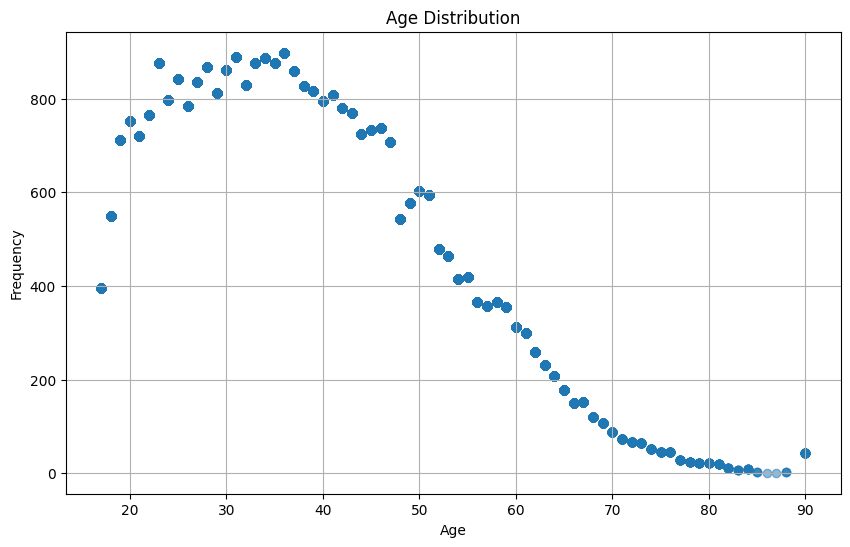

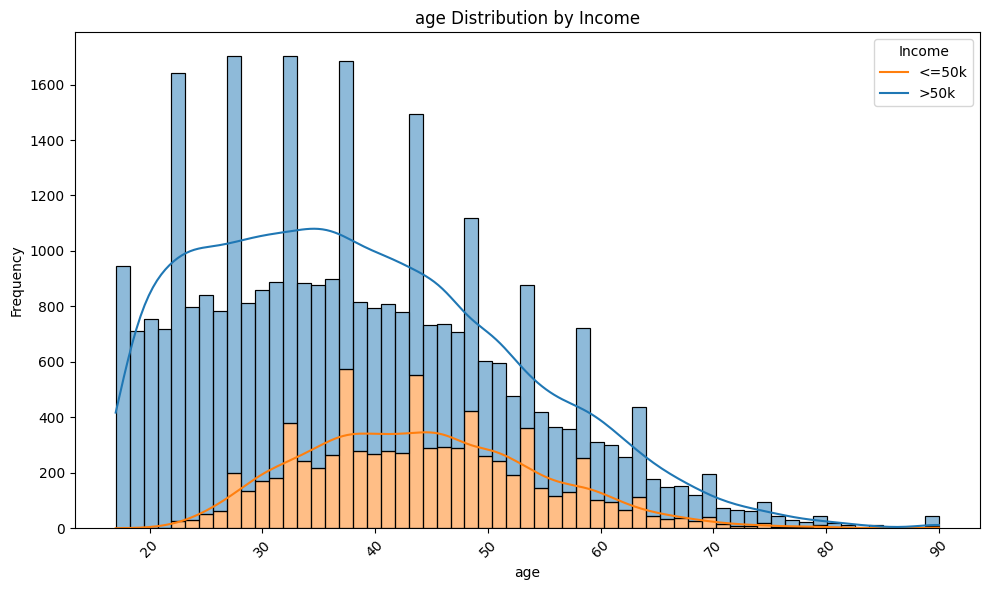

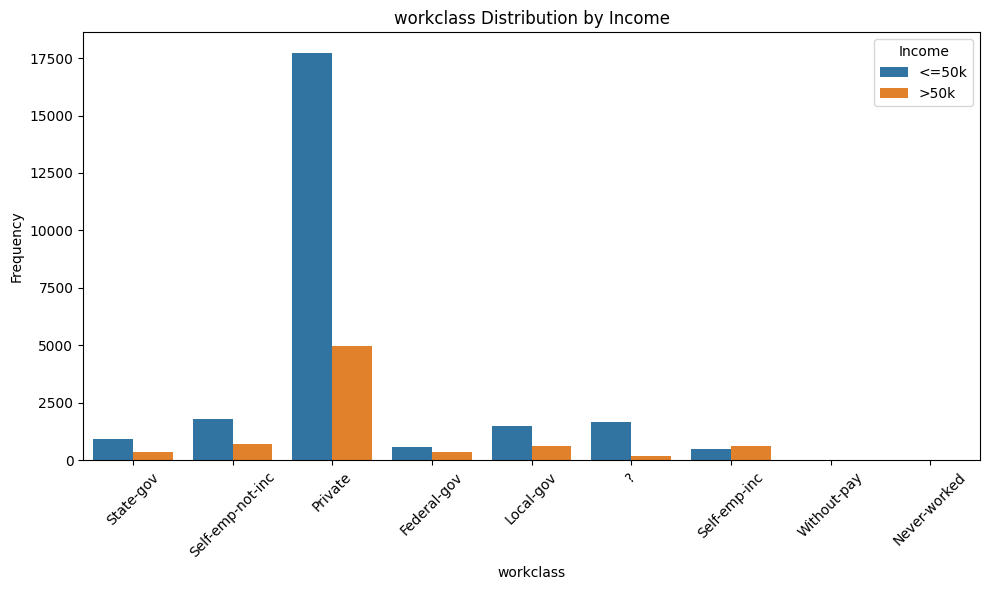

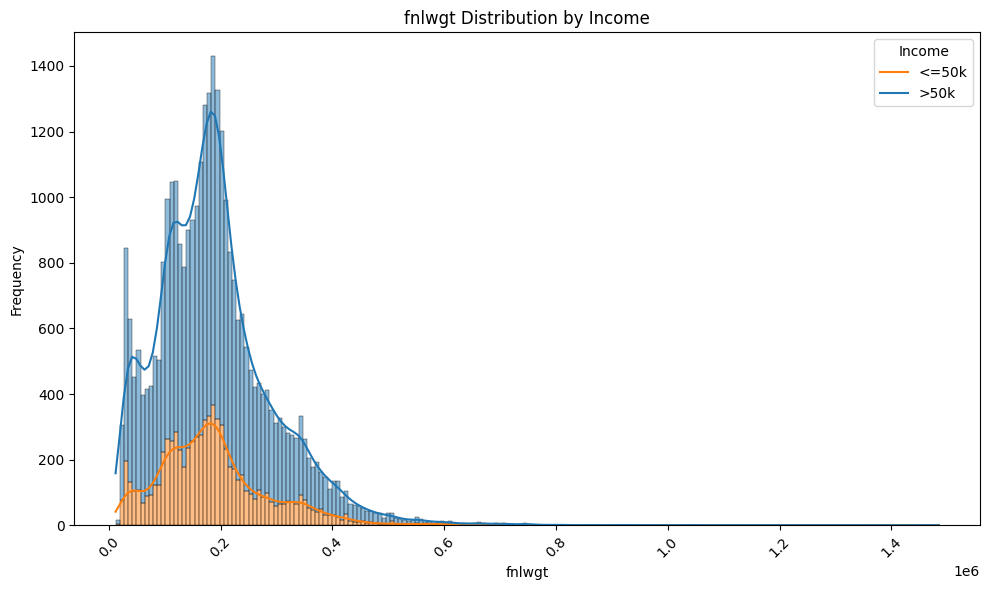

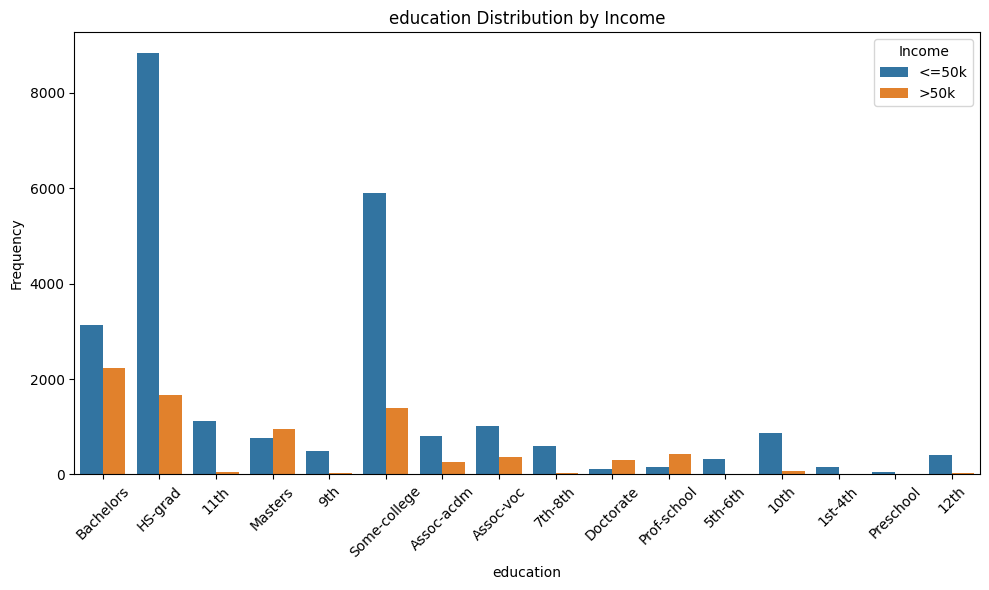

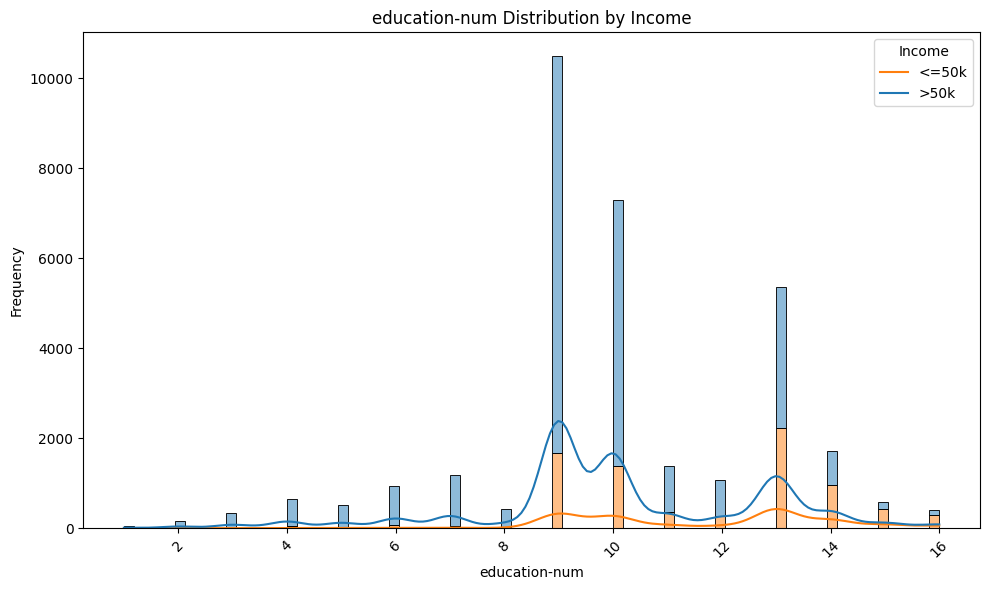

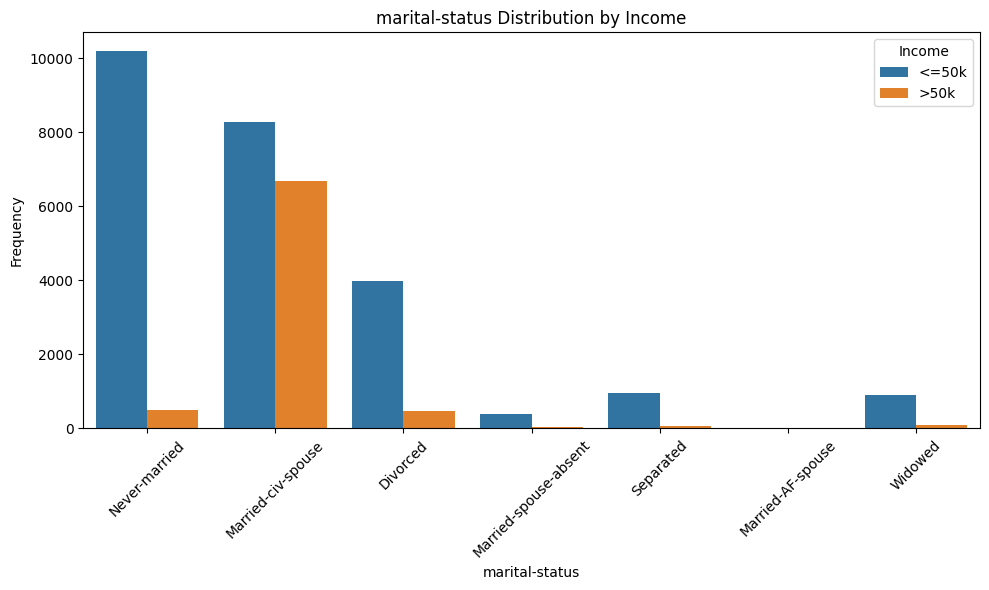

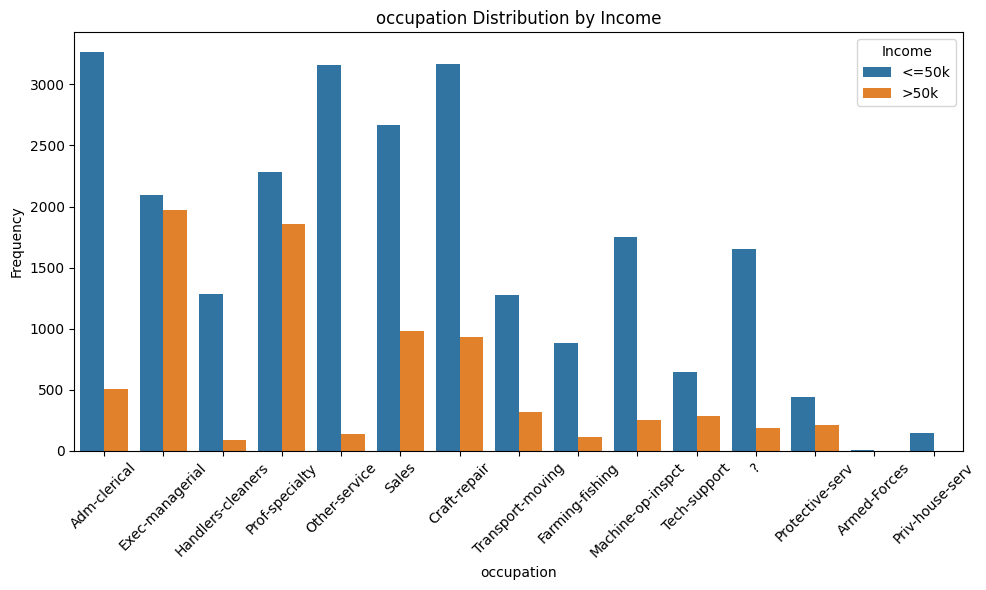

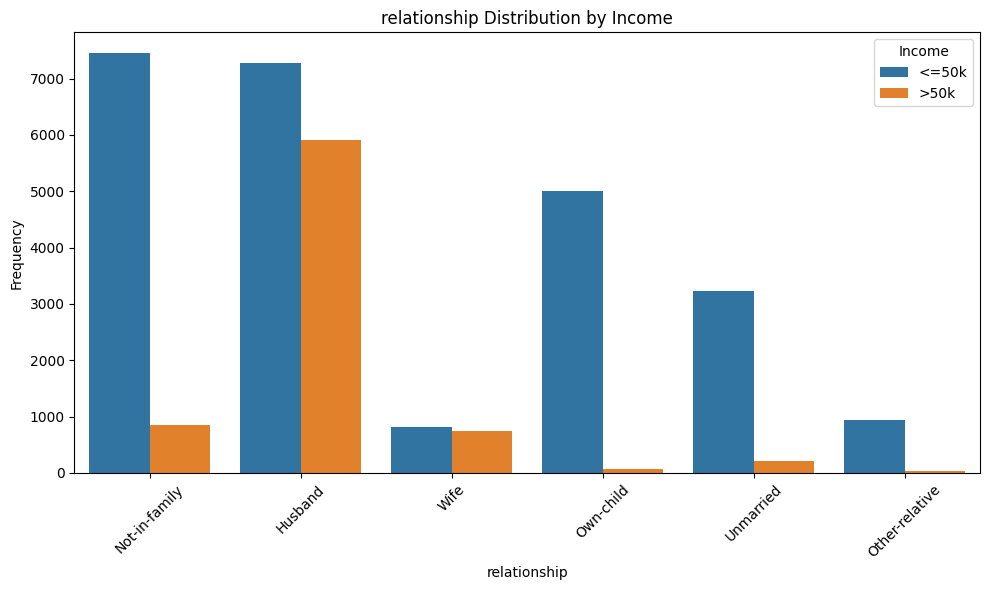

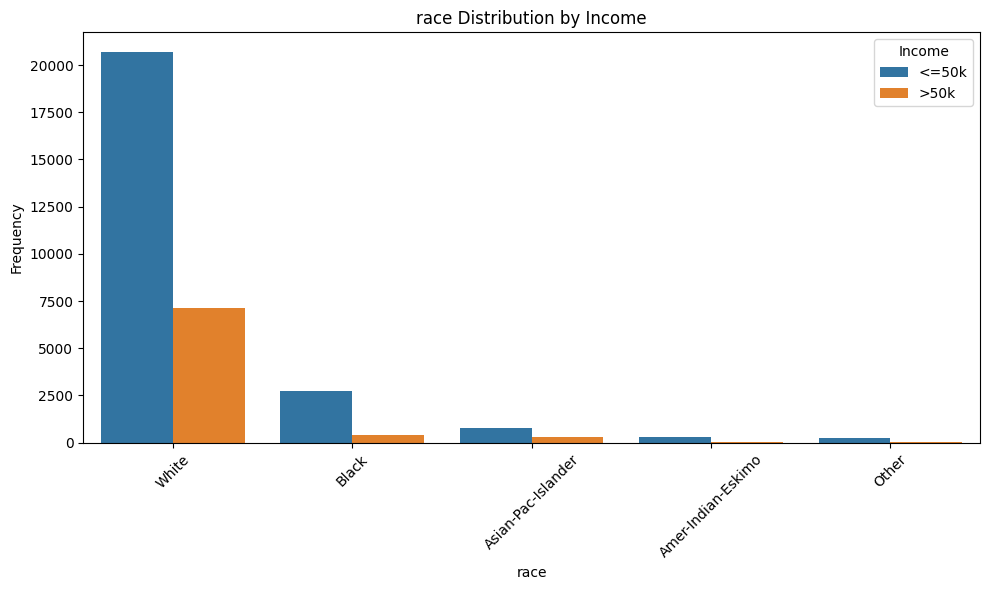

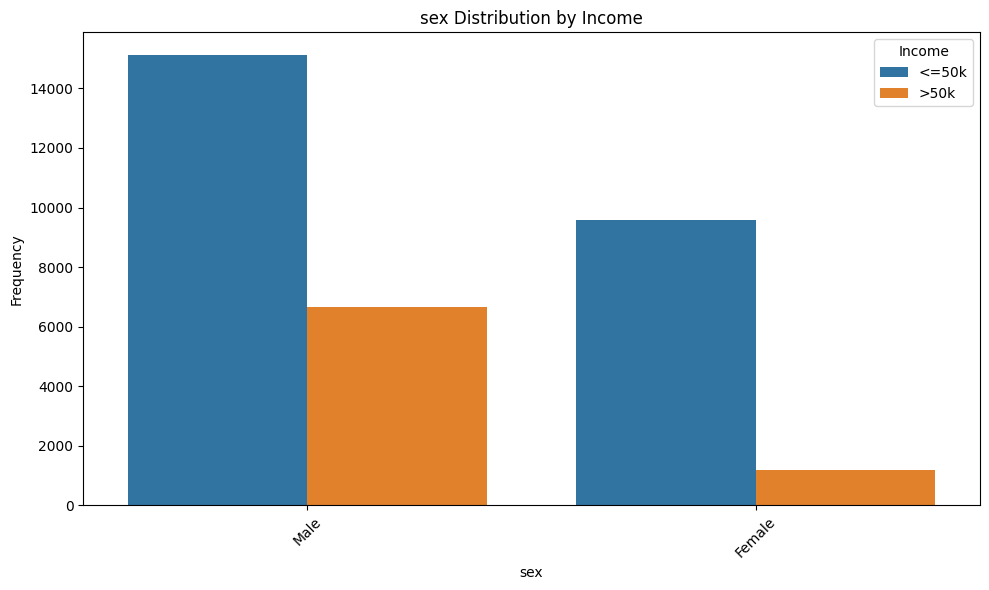

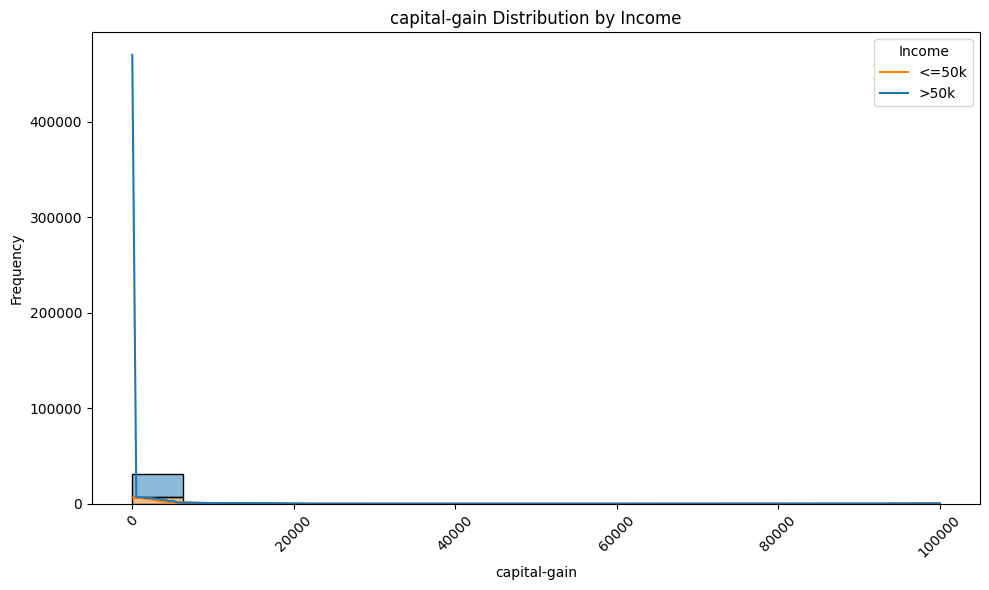

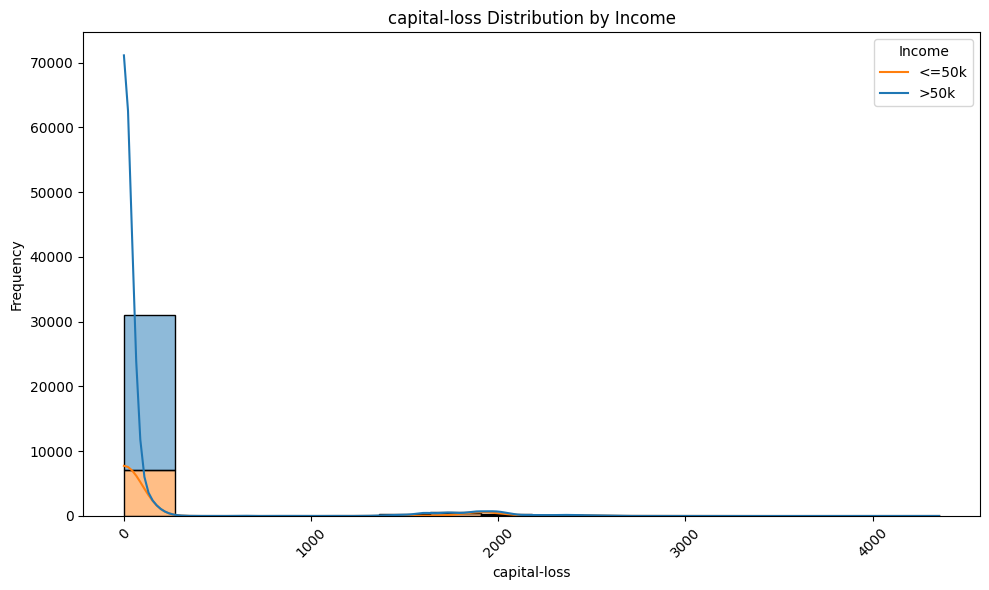

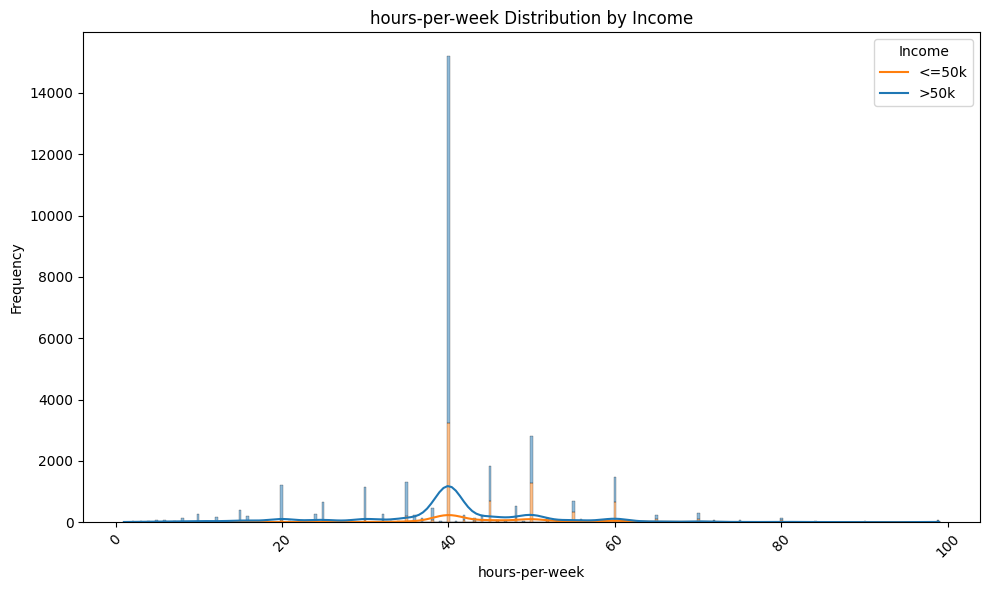

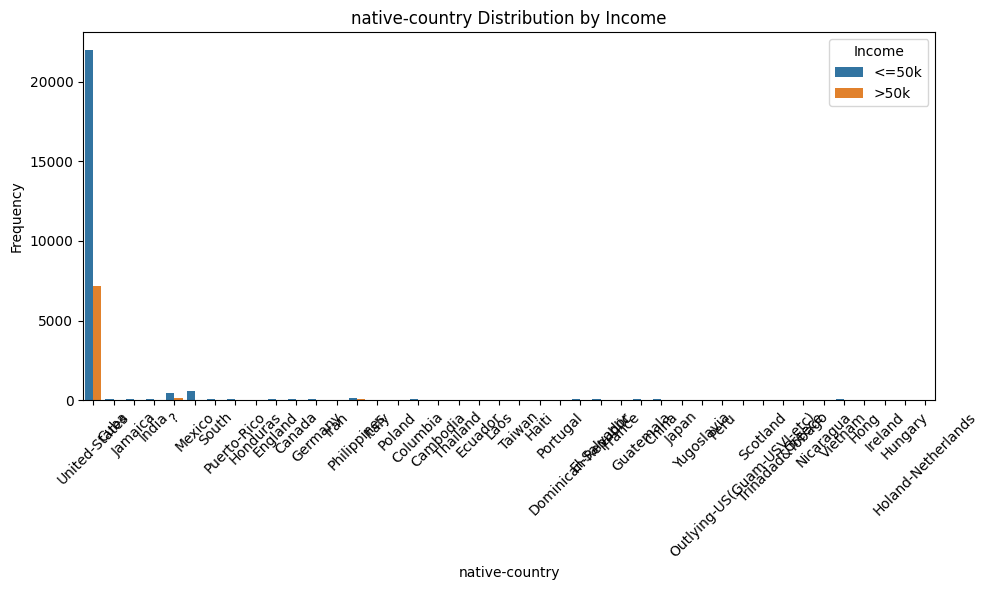

In [127]:
# Plotting the age distribution
age_values = ds_train['age'].values
age_counts = ds_train['age'].value_counts()

# Create scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(age_values, [age_counts[age] for age in age_values], alpha=0.5)
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age Distribution')
plt.grid(True)
plt.show()

# features vs income
def plot_column_vs_income(df, column):
    plt.figure(figsize=(10, 6))
    if df[column].dtype == 'object':
        sns.countplot(x=column, hue='income', data=df)
    else:
        sns.histplot(data=df, x=column, hue='income', multiple='stack', kde=True)
    plt.xlabel(column)
    plt.ylabel('Frequency')
    plt.title(f'{column} Distribution by Income')
    plt.legend(title='Income', labels=['<=50k', '>50k'])
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Plot each column against income
for column in ds_train.columns:
    if column != 'income':
        plot_column_vs_income(ds_train, column)

TRAIN DATA CLEANING

In [128]:
# missing values
ds_train.replace("?", pd.NA, inplace=True)

nan_columns = ds_train.columns[ds_train.isnull().any()]  # identify columns with null values
print(ds_train[nan_columns].isnull().sum())  # display the count of null values in each column

# replace null values with mode
for column in nan_columns:
    ds_train[column].fillna(ds_train[column].mode().values[0], inplace=True)

# duplicate entries
ds_train.drop_duplicates(inplace=True)

# converting to lowercase
ds_train = ds_train.apply(lambda x: x.str.lower() if x.dtype == "object" else x)

# remove outliers in 'age' feature
ds_train = ds_train[(np.abs(stats.zscore(ds_train['age'])) < 3)]

# binarize native-country
ds_train['native-country'] = ds_train['native-country'].apply(lambda x: 1 if x.strip() == 'United-States' else 0)

# total capital
ds_train['total-capital'] = ds_train['capital-gain'] - ds_train['capital-loss']

# removin useless column
ds_train.drop(['fnlwgt', 'education', 'capital-gain', 'capital-loss'], axis=1, inplace=True)

workclass         1836
occupation        1843
native-country     583
dtype: int64


<class 'pandas.core.frame.DataFrame'>
Int64Index: 32417 entries, 0 to 32560
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32417 non-null  int64 
 1   workclass       32417 non-null  object
 2   education-num   32417 non-null  int64 
 3   marital-status  32417 non-null  object
 4   occupation      32417 non-null  object
 5   relationship    32417 non-null  object
 6   race            32417 non-null  object
 7   sex             32417 non-null  object
 8   hours-per-week  32417 non-null  int64 
 9   native-country  32417 non-null  int64 
 10  income          32417 non-null  object
 11  total-capital   32417 non-null  int64 
dtypes: int64(5), object(7)
memory usage: 3.2+ MB
None
   age         workclass  education-num      marital-status  \
0   39         state-gov             13       never-married   
1   50  self-emp-not-inc             13  married-civ-spouse   
2   38           private       

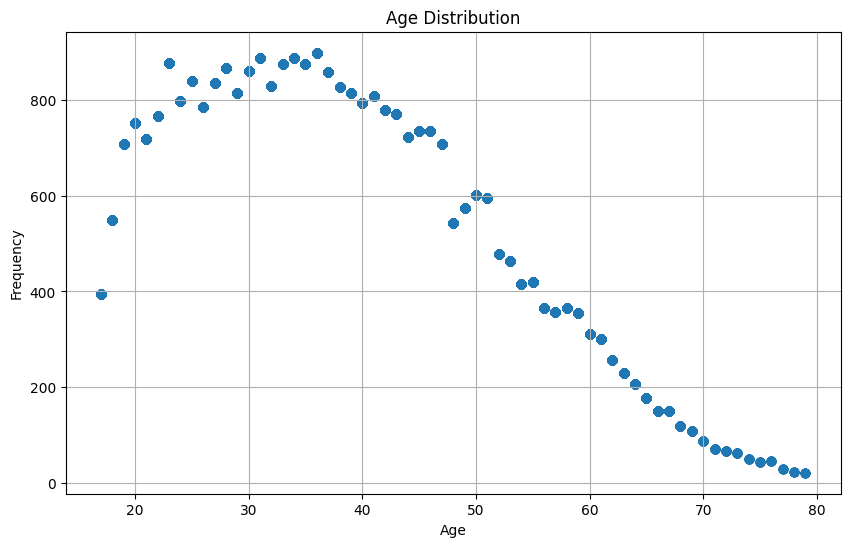

In [129]:
print(ds_train.info())
print(ds_train.head())
# Plotting the age distribution
age_values = ds_train['age'].values
age_counts = ds_train['age'].value_counts()

# Create scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(age_values, [age_counts[age] for age in age_values], alpha=0.5)
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age Distribution')
plt.grid(True)
plt.show()

In [130]:
# ds_train.to_csv('cleaned_dataset.csv', index=False)

In [131]:
#seperating categorical features
categorical_features = list(ds_train.select_dtypes(include=['object']).columns)
print(categorical_features)

#seperating numerical features
numerical_features = list(ds_train.select_dtypes(include=['int64', 'float64']).columns)
print(numerical_features)

['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'income']
['age', 'education-num', 'hours-per-week', 'native-country', 'total-capital']


In [132]:
print(ds_train.head())

   age         workclass  education-num      marital-status  \
0   39         state-gov             13       never-married   
1   50  self-emp-not-inc             13  married-civ-spouse   
2   38           private              9            divorced   
3   53           private              7  married-civ-spouse   
4   28           private             13  married-civ-spouse   

          occupation   relationship   race     sex  hours-per-week  \
0       adm-clerical  not-in-family  white    male              40   
1    exec-managerial        husband  white    male              13   
2  handlers-cleaners  not-in-family  white    male              40   
3  handlers-cleaners        husband  black    male              40   
4     prof-specialty           wife  black  female              40   

   native-country income  total-capital  
0               0  <=50k           2174  
1               0  <=50k              0  
2               0  <=50k              0  
3               0  <=50k        

TEST DATA

In [133]:
# load testing dataset

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test"

columns = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status", "occupation",
           "relationship", "race", "sex", "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"]

ds_test = pd.read_csv(url, names=columns, na_values=" ?", skipinitialspace=True, skiprows=1) # avoiding "|1x3 Cross validator" string
print(ds_test.info())
print(ds_test.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16281 entries, 0 to 16280
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             16281 non-null  int64 
 1   workclass       16281 non-null  object
 2   fnlwgt          16281 non-null  int64 
 3   education       16281 non-null  object
 4   education-num   16281 non-null  int64 
 5   marital-status  16281 non-null  object
 6   occupation      16281 non-null  object
 7   relationship    16281 non-null  object
 8   race            16281 non-null  object
 9   sex             16281 non-null  object
 10  capital-gain    16281 non-null  int64 
 11  capital-loss    16281 non-null  int64 
 12  hours-per-week  16281 non-null  int64 
 13  native-country  16281 non-null  object
 14  income          16281 non-null  object
dtypes: int64(6), object(9)
memory usage: 1.9+ MB
None
   age  workclass  fnlwgt     education  education-num      marital-status  \
0   25    

TEST DATA CLEANING

In [134]:

# convert false dtypes
ds_test['age'] = ds_test['age'].astype(int)
ds_test['fnlwgt'] = ds_test['fnlwgt'].astype(int)
ds_test['education-num'] = ds_test['education-num'].astype(int)
ds_test['capital-gain'] = ds_test['capital-gain'].astype(int)
ds_test['capital-loss'] = ds_test['capital-loss'].astype(int)
ds_test['hours-per-week'] = ds_test['hours-per-week'].astype(int)

# missing values
ds_test.replace("?", pd.NA, inplace=True)

nan_columns_test = ds_test.columns[ds_test.isnull().any()]  # Identify columns with null values
print(ds_test[nan_columns_test].isnull().sum())  # Display the count of null values in each column

# replace null values with mode
for column in nan_columns_test:
    ds_test[column].fillna(ds_test[column].mode().values[0], inplace=True)

# duplicate entries
ds_test.drop_duplicates(inplace=True)

# converting to lowercase
ds_test = ds_test.apply(lambda x: x.str.lower() if x.dtype == "object" else x)

# remove outliers in 'age' feature
ds_test = ds_test[(np.abs(stats.zscore(ds_test['age'])) < 3)]

# binarize
ds_test['native-country'] = ds_test['native-country'].apply(lambda x: 1 if x.strip() == 'United-States' else 0)

# total capital
ds_test['total-capital'] = ds_test['capital-gain'] - ds_test['capital-loss']

# removin useless column
ds_test.drop(['fnlwgt', 'education', 'capital-gain', 'capital-loss'], axis=1, inplace=True)

print(ds_test.info())

workclass         963
occupation        966
native-country    274
dtype: int64
<class 'pandas.core.frame.DataFrame'>
Int64Index: 16227 entries, 0 to 16280
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             16227 non-null  int64 
 1   workclass       16227 non-null  object
 2   education-num   16227 non-null  int64 
 3   marital-status  16227 non-null  object
 4   occupation      16227 non-null  object
 5   relationship    16227 non-null  object
 6   race            16227 non-null  object
 7   sex             16227 non-null  object
 8   hours-per-week  16227 non-null  int64 
 9   native-country  16227 non-null  int64 
 10  income          16227 non-null  object
 11  total-capital   16227 non-null  int64 
dtypes: int64(5), object(7)
memory usage: 1.6+ MB
None


LABEL ENCODING

In [135]:

le = preprocessing.LabelEncoder()
for i in categorical_features:
    ds_train[i] = le.fit_transform(ds_train[i])
    ds_test[i] = le.fit_transform(ds_test[i])


In [136]:
print(ds_train.head())

   age  workclass  education-num  marital-status  occupation  relationship  \
0   39          6             13               4           0             1   
1   50          5             13               2           3             0   
2   38          3              9               0           5             1   
3   53          3              7               2           5             0   
4   28          3             13               2           9             5   

   race  sex  hours-per-week  native-country  income  total-capital  
0     4    1              40               0       0           2174  
1     4    1              13               0       0              0  
2     4    1              40               0       0              0  
3     2    1              40               0       0              0  
4     2    0              40               0       0              0  


In [137]:
print(ds_test.head())

   age  workclass  education-num  marital-status  occupation  relationship  \
0   25          3              7               4           6             3   
1   38          3              9               2           4             0   
2   28          1             12               2          10             0   
3   44          3             10               2           6             0   
4   18          3             10               4           9             3   

   race  sex  hours-per-week  native-country  income  total-capital  
0     2    1              40               0       0              0  
1     4    1              50               0       0              0  
2     4    1              40               0       1              0  
3     2    1              40               0       1           7688  
4     4    0              30               0       0              0  


SEPERATING FEATURES AND TARGET FOR TRAINING

In [138]:

X1 = ds_train.drop('income', axis=1)
y1 = ds_train['income']

print("Training set:")
print(X1.head())


Training set:
   age  workclass  education-num  marital-status  occupation  relationship  \
0   39          6             13               4           0             1   
1   50          5             13               2           3             0   
2   38          3              9               0           5             1   
3   53          3              7               2           5             0   
4   28          3             13               2           9             5   

   race  sex  hours-per-week  native-country  total-capital  
0     4    1              40               0           2174  
1     4    1              13               0              0  
2     4    1              40               0              0  
3     2    1              40               0              0  
4     2    0              40               0              0  


OVERSAMPLING

In [139]:
from imblearn.over_sampling import SMOTE

# instantiate SMOTE
smote = SMOTE(sampling_strategy=1, random_state=42)

# oversampling on the training data
X, y = smote.fit_resample(X1, y1)

# shape of the resampled data
print("Shape of X resampled:", X.shape)
print("Shape of y resampled:", y.shape)

print("Class distribution after SMOTE:")
print(y.value_counts())

Shape of X resampled: (49188, 11)
Shape of y resampled: (49188,)
Class distribution after SMOTE:
0    24594
1    24594
Name: income, dtype: int64


TRAINING AND TESTING THE MODELS

In [140]:
# Naive bayes
naive_bayes = GaussianNB()
naive_bayes.fit(X, y)

# Random Forest Classifier
random_forest = RandomForestClassifier(random_state=42)
random_forest.fit(X, y)

# Predictions for Naive Bayes on training data
naive_bayes_train_pred = naive_bayes.predict(X)

# Predictions for Random Forest Classifier on training data
random_forest_train_pred = random_forest.predict(X)

# Classification report for Naive Bayes on training data
print("Classification Report - Naive Bayes on Training Data:")
print(classification_report(y, naive_bayes_train_pred))

# Classification report for Random Forest Classifier on training data
print("\nClassification Report - Random Forest on Training Data:")
print(classification_report(y, random_forest_train_pred))


Classification Report - Naive Bayes on Training Data:
              precision    recall  f1-score   support

           0       0.65      0.93      0.77     24594
           1       0.88      0.50      0.64     24594

    accuracy                           0.72     49188
   macro avg       0.77      0.72      0.71     49188
weighted avg       0.77      0.72      0.71     49188


Classification Report - Random Forest on Training Data:
              precision    recall  f1-score   support

           0       0.98      0.96      0.97     24594
           1       0.96      0.98      0.97     24594

    accuracy                           0.97     49188
   macro avg       0.97      0.97      0.97     49188
weighted avg       0.97      0.97      0.97     49188



In [141]:
# Predictions for Naive Bayes
naive_bayes_pred = naive_bayes.predict(ds_test.drop('income', axis=1))

# Predictions for Random Forest Classifier
random_forest_pred = random_forest.predict(ds_test.drop('income', axis=1))

# Classification report for Naive Bayes on test data
print("Classification Report - Naive Bayes on Test Data:")
print(classification_report(ds_test['income'], naive_bayes_pred))

# Classification report for Random Forest Classifier on test data
print("\nClassification Report - Random Forest on Test Data:")
print(classification_report(ds_test['income'], random_forest_pred))

Classification Report - Naive Bayes on Test Data:
              precision    recall  f1-score   support

           0       0.86      0.94      0.90     12392
           1       0.71      0.50      0.59      3835

    accuracy                           0.83     16227
   macro avg       0.78      0.72      0.74     16227
weighted avg       0.82      0.83      0.82     16227


Classification Report - Random Forest on Test Data:
              precision    recall  f1-score   support

           0       0.91      0.87      0.89     12392
           1       0.62      0.72      0.67      3835

    accuracy                           0.83     16227
   macro avg       0.77      0.79      0.78     16227
weighted avg       0.84      0.83      0.84     16227



In [142]:

# error for Naive Bayes
accuracy_nb = accuracy_score(ds_test['income'], naive_bayes_pred)
error_nb = 1 - accuracy_nb

print("Error for Naive Bayes:", error_nb)

# error for Random Forest Classifier
accuracy_rf = accuracy_score(ds_test['income'], random_forest_pred)
error_rf = 1 - accuracy_rf

print("Error for Random Forest Classifier:", error_rf)


Error for Naive Bayes: 0.1661428483391878
Error for Random Forest Classifier: 0.1687927528193751


CONFUSION MATRICES

[[11609   783]
 [ 1913  1922]]


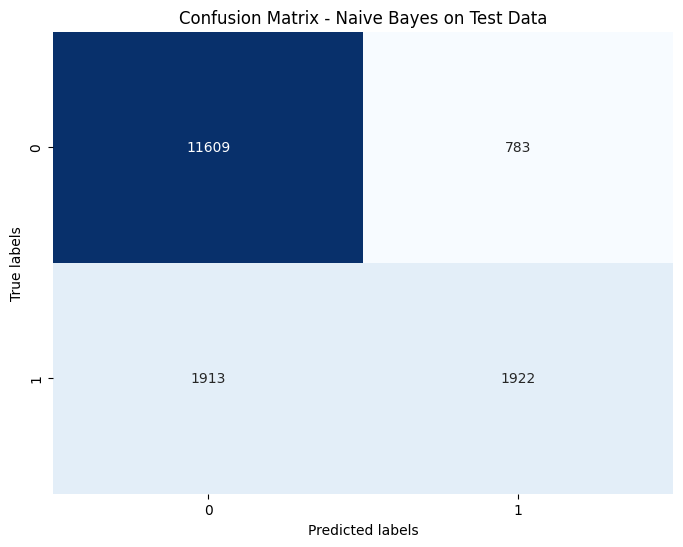

[[10721  1671]
 [ 1068  2767]]


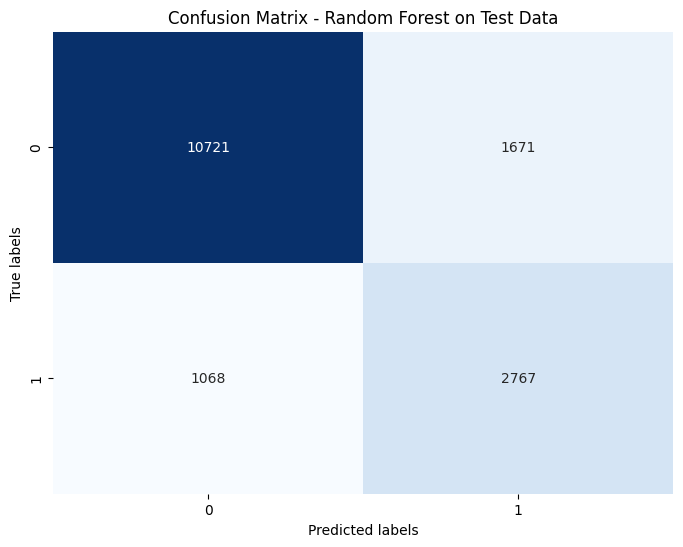

In [143]:

# confusion matrix for Naive Bayes on test data
cm_nb_test = confusion_matrix(ds_test['income'], naive_bayes_pred)
print(cm_nb_test)
# confusion matrix for Naive Bayes on test data
plt.figure(figsize=(8, 6))
sns.heatmap(cm_nb_test, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix - Naive Bayes on Test Data')
plt.show()

# confusion matrix for Random Forest Classifier on test data
cm_rf_test = confusion_matrix(ds_test['income'], random_forest_pred)
print(cm_rf_test)
# confusion matrix for Random Forest Classifier on test data
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf_test, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix - Random Forest on Test Data')
plt.show()

ROC CURVES

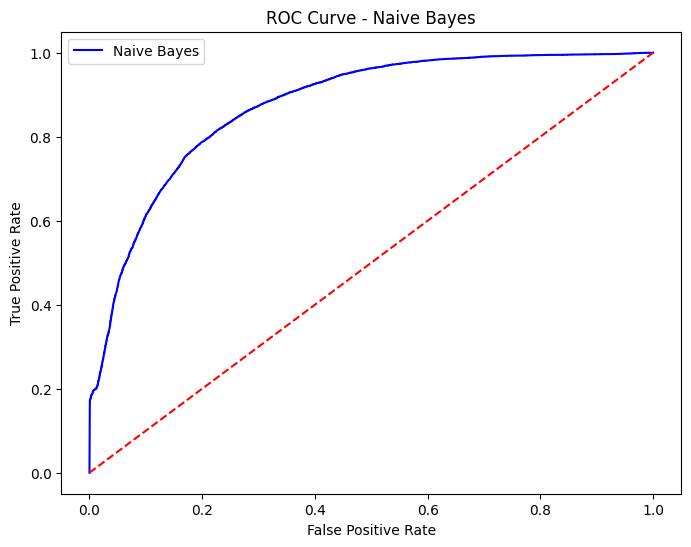

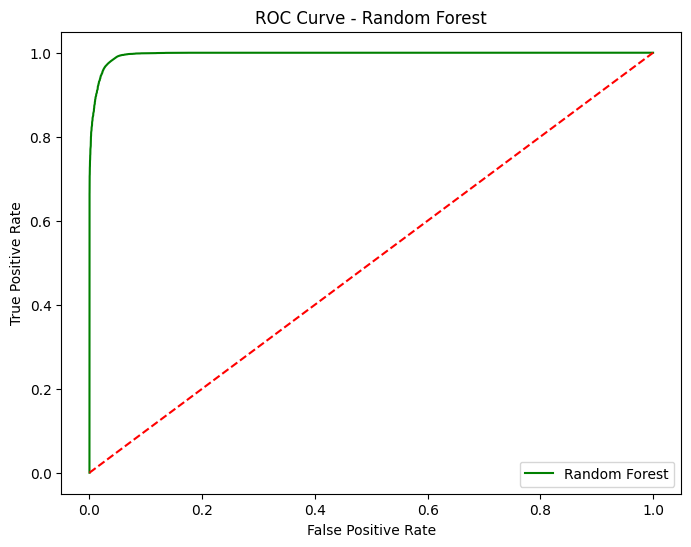

In [144]:

naive_bayes_probs = naive_bayes.predict_proba(X)[:, 1]
fpr_nb, tpr_nb, _ = roc_curve(y, naive_bayes_probs)

plt.figure(figsize=(8, 6))
plt.plot(fpr_nb, tpr_nb, color='blue', label='Naive Bayes')
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Naive Bayes')
plt.legend()
plt.show()

random_forest_probs = random_forest.predict_proba(X)[:, 1]
fpr_rf, tpr_rf, _ = roc_curve(y, random_forest_probs)

plt.figure(figsize=(8, 6))
plt.plot(fpr_rf, tpr_rf, color='green', label='Random Forest')
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest')
plt.legend()
plt.show()


In [145]:
nb_probs = naive_bayes.predict_proba(ds_test.drop('income', axis=1))[:, 1]

#ROC curve for Naive Bayes
fpr_nb, tpr_nb, _ = roc_curve(ds_test['income'], nb_probs)

# AUC for Naive Bayes
auc_nb = roc_auc_score(ds_test['income'], nb_probs)
print("AUC for Naive Bayes:", auc_nb)

# probabilities for Random Forest
rf_probs = random_forest.predict_proba(ds_test.drop('income', axis=1))[:, 1]

# ROC curve for Random Forest
fpr_rf, tpr_rf, _ = roc_curve(ds_test['income'], rf_probs)

# AUC for Random Forest
auc_rf = roc_auc_score(ds_test['income'], rf_probs)
print("AUC for Random Forest:", auc_rf)

AUC for Naive Bayes: 0.8669848928904799
AUC for Random Forest: 0.8893049138822793


PRECISION-RECALL CURVES

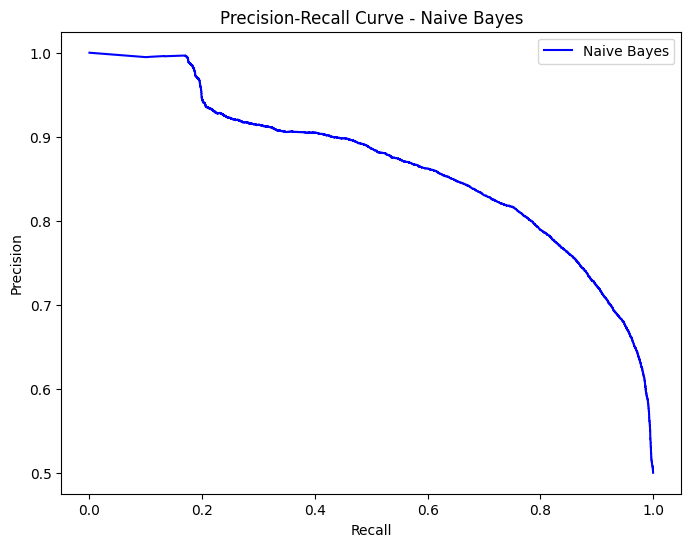

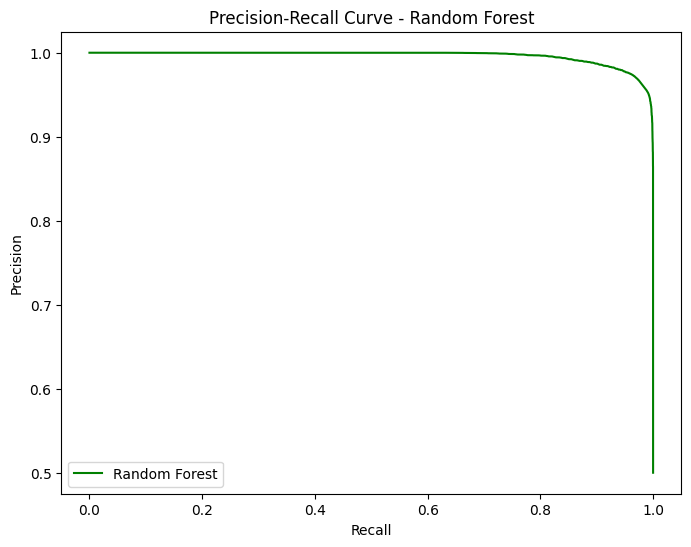

In [146]:
# Precision-Recall curve for Naive Bayes

precision_nb, recall_nb, _ = precision_recall_curve(y, naive_bayes_probs)

plt.figure(figsize=(8, 6))
plt.plot(recall_nb, precision_nb, color='blue', label='Naive Bayes')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Naive Bayes')
plt.legend()
plt.show()

# Precision-Recall curve for Random Forest
precision_rf, recall_rf, _ = precision_recall_curve(y, random_forest_probs)

plt.figure(figsize=(8, 6))
plt.plot(recall_rf, precision_rf, color='green', label='Random Forest')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Random Forest')
plt.legend()
plt.show()